Cloning into 'mm-bem'...
remote: Enumerating objects: 330, done.
remote: Counting objects: 100% (330/330), done.
remote: Compressing objects: 100% (329/329), done.
remote: Total 330 (delta 158), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (330/330), 12.13 MiB | 8.80 MiB/s, done.
Resolving deltas: 100% (158/158), done.


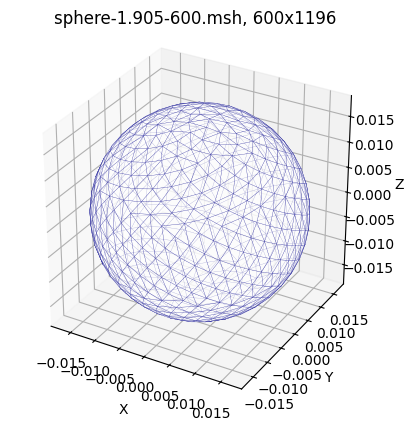

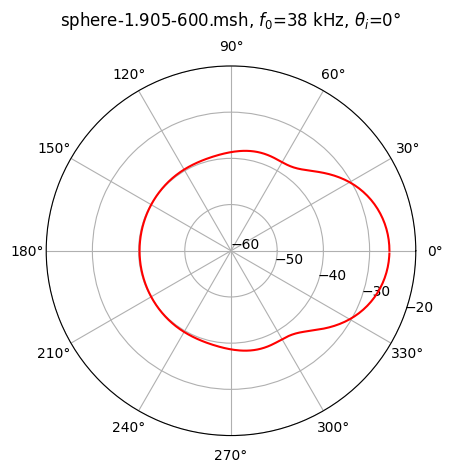

#deg	lbs
0	0.0518485
1	0.0518184
2	0.0517279
3	0.0515774
4	0.0513674
5	0.0510983
6	0.0507712
7	0.050387
8	0.0499469
9	0.0494524
10	0.0489048
11	0.048306
12	0.0476577
13	0.0469621
14	0.0462211
15	0.0454372
16	0.0446127
17	0.0437502
18	0.0428523
19	0.0419218
20	0.0409615
21	0.0399744
22	0.0389635
23	0.0379319
24	0.0368828
25	0.0358194
26	0.0347449
27	0.0336628
28	0.0325763
29	0.0314889
30	0.030404
31	0.029325
32	0.0282554
33	0.0271986
34	0.0261582
35	0.0251375
36	0.0241401
37	0.0231694
38	0.0222286
39	0.0213212
40	0.0204504
41	0.0196192
42	0.0188305
43	0.0180872
44	0.0173916
45	0.0167458
46	0.0161514
47	0.0156098
48	0.0151214
49	0.0146862
50	0.0143036
51	0.0139721
52	0.0136895
53	0.0134533
54	0.0132601
55	0.0131062
56	0.0129874
57	0.0128996
58	0.0128384
59	0.0127995
60	0.0127789
61	0.0127725
62	0.0127768
63	0.0127886
64	0.0128049
65	0.0128231
66	0.0128411
67	0.012857
68	0.0128692
69	0.0128766
70	0.0128781
71	0.012873
72	0.0128609
73	0.0128415
74	0.0128146
75	0.0127803
76	0.0127389
77	0.0

In [37]:
#!pip install -q numpy scipy matplotlib

import os
repo_name = "mm-bem"
repo_url = f"https://github.com/marmoszy/{repo_name}.git"

if not os.path.exists(repo_name): 
    !git clone {repo_url}
os.chdir(f"{repo_name}/msh")

from numpy import pi, sqrt, exp, sin, cos, log10, array, zeros, linspace
from scipy.linalg import lu_factor, lu_solve
import matplotlib.pyplot as plt

fname = 'sphere-1.905-600.msh'
th = 0
f0 = 38e3
c0 = 1480

k = 2 * pi * f0 / c0
d = [cos(pi / 180 * th), sin(pi / 180 * th), 0]

with open(fname) as f: lines = f.readlines()
n = int(lines[4])
v = [list(map(float, lines[5 + i].split()[1:4])) for i in range(n)]
m = int(lines[n + 7])
e = [list(map(int, lines[n + 8 + i].split()[5:8])) for i in range(m)]

x = [sum([array(v[e[i][j] - 1]) / 3 for j in range(3)]) for i in range(m)]

S = zeros((m, m), dtype=complex)
for i in range(m):
    for j in range(m):
        r = sqrt(sum((x[i] - x[j]) ** 2))
        S[i][j] = exp(1j * k * r) / r / (4 * pi) if r != 0 else 1j * k / (4 * pi)

f_inc = array([exp(1j * k * p @ d) for p in x])

phi = lu_solve(lu_factor(S), -f_inc)

r1 = [[cos(pi / 180 * i), sin(pi / 180 * i), 0] for i in range(360)]
S_far = [[exp(-1j * k * p @ r) / (4 * pi) for p in x] for r in r1]
psc = S_far @ phi

# plot mesh
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
tri = [[array(v[i-1]) for i in t] for t in e]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
mesh_collection = Poly3DCollection(tri, alpha=0.6)
mesh_collection.set_facecolor('white')
mesh_collection.set_edgecolor('darkblue')
mesh_collection.set_linewidth(0.2)
ax.add_collection3d(mesh_collection)
v_arr = array(v)
ax.set_xlim(v_arr[:, 0].min(), v_arr[:, 0].max())
ax.set_ylim(v_arr[:, 1].min(), v_arr[:, 1].max())
ax.set_zlim(v_arr[:, 2].min(), v_arr[:, 2].max())
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title(r"%s, %dx%d"%(fname,n,m))
plt.show()

# plot solution
import matplotlib.pyplot as plt
angles = linspace(0, 2 * pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, color='red')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title(r"%s, $f_0$=%g kHz, $\theta_i$=%g$\degree$"%(fname,f0/1e3,th), va='bottom')
plt.show()

print("#deg\tlbs")
for i in range(360):
    print(f"{i}\t{abs(psc[i]):g}")
